# Measure learned-plan performance across deposit shapes

**Question:** How does the learned plan's value compare with exact ExTS across distinct synthetic deposit archetypes, and where should its guard speak?

**Level:** 2 · The method in practice

**Prerequisites:** Complete learned-surrogate level 1.

**Reading time:** 26 minutes

## Objectives

The product dossier evaluates the learned method across disjoint deposit seeds, scenarios and grid sizes because blocks from one deposit share features. This lesson builds four small synthetic archetypes, loads one frozen model bundle, and measures each learned plan against its exact expected-time plan on the same case. The ratio is a case-specific measurement, not a forecast for an unseen real deposit. You will also run the shipped guard rule and compare its clean third-split recall with the tempting but biased held-out recall. The lesson is about how to evaluate a surrogate honestly: preserve deposit-level splits, show failures, and never let a prediction replace the bound. Small teaching twins expose the path but cannot reproduce the full 1,008- and 6,912-block validation population.

## Setup

Install the pinned environment from the repository root with `python -m pip install -r notebooks/requirements.txt`. This lesson uses `oreblocks==0.6.3`. Model files are committed; this notebook does not train or install anything.

```bash
python -m pip install -r notebooks/requirements.txt
```

In [1]:
# Load the pipeline and the committed learned-model bundle.
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
from pipeline.model.learned import LearnedBundle
import oreblocks as ob
print('oreblocks', metadata.version('oreblocks'))

oreblocks 0.6.3


## Data

Inputs are generated through PhaseFlow's MIT-licensed instance pipeline. The model bundle is the committed set `models/expected-time.json`, `models/bound.json`, and `models/guard-validation.json`; these are model artifacts from the product's synthetic training study, not observations from a named mine. OreBlocks 0.6.3 supplies the TopoSort schedule and exact expected-time baseline. The learned model was trained with deposits separated by seed: twelve training seeds, six held-out seeds and a third disjoint validation set. These small lesson instances use new declared seeds. Never interpret their scores as replacing the persisted validation report or as evidence about a real block model.

## Method



In [2]:
# Build a seeded core-halo teaching case through PhaseFlow.
case = Case(
    id='learned-core-halo-8x8x4', category='teaching',
    title_en='Core halo surrogate lesson', title_es='Leccion surrogate core halo',
    deposit=DepositSpec(kind='twin', archetype='core_halo', dims=(8, 8, 4), seed=223),
    scenario=Scenario(periods=6, discount_rate=0.10,
        capacity_fraction=(0.85, 0.55), resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contract:', instance.report.ok, '| blocks:', instance.n_blocks)

contract: True | blocks: 256


In [3]:
# Load model artifacts from the repository and inspect the persisted study.
bundle = LearnedBundle.load(Path('../../../models'))
report = bundle.report()
print('held-out expected-time Spearman:', report['expectedTime'].get('holdout_spearman'))
print('clean guard recall:', report['guard'].get('validation_recall'))
print('guard failures:', report['guard'].get('validation_failures'), '/', report['guard'].get('validation_n'))

held-out expected-time Spearman: 0.8070491200859878
clean guard recall: 0.47183098591549294
guard failures: 142 / 432


Create four cases with shared dimensions and scenario settings, changing only archetype and seed. That paired design makes a per-case value ratio interpretable.

In [4]:
# Declare the crossed teaching cases; only archetype and seed vary.
archetypes = ('porphyry', 'vein', 'layered', 'core_halo')
cases = []
for seed, kind in enumerate(archetypes, start=223):
    cases.append(Case(
        id=f'learned-{kind}', category='teaching', title_en=kind, title_es=kind,
        deposit=DepositSpec(kind='twin', archetype=kind, dims=(8, 8, 4), seed=seed),
        scenario=Scenario(
            periods=6, discount_rate=0.10, capacity_fraction=(0.85, 0.55),
            resource_names=('mining', 'processing'),
        ),
    ))
instances = [build_instance(case) for case in cases]
print([(case.deposit.archetype, inst.n_blocks) for case, inst in zip(cases, instances)])

[('porphyry', 256), ('vein', 256), ('layered', 256), ('core_halo', 256)]


Run the bound surrogate on the same generated cases. Preserve its estimates as predictions and compare them with exact bounds in a separate validation study.

In [5]:
# Predict one bound ratio per case without treating it as a certificate.
bound_ratios = [bundle.predict_bound_ratio(inst, case.scenario) for inst, case in zip(instances, cases)]
print('predicted ratios:', np.round(bound_ratios, 3))

predicted ratios: [0.473 0.456 0.491 0.349]


Run the learned path on every case and retain one result per deposit. This is still a toy sweep, not the model's disjoint study.

In [6]:
# Infer a learned schedule for each generated deposit.
learned = [bundle.for_instance(instance)[0][1] for instance in instances]
print([(instance.archetype, round(result.npv, 2)) for instance, result in zip(instances, learned)])

[('porphyry', 5364732.02), ('vein', 5838520.47), ('layered', 28685489.55), ('core_halo', 1292857.61)]


Compute exact ExTS results on the same instances, then take ratios before any summary. A ratio near one is a measured match for that deposit; it says nothing about deposits outside this small set.

In [7]:
# Run exact expected-time plans and compute paired per-deposit ratios.
exact = [ob.solve_cpit(inst.cpit, inst.precedence, method='expected', local_search=False)[0] for inst in instances]
ratios = np.array([learned[i].npv / exact[i].npv for i in range(len(instances))])
print('ratios:', np.round(ratios, 3))
print('mean:', round(float(ratios.mean()), 3), '| minimum:', round(float(ratios.min()), 3))

ratios: [0.971 0.881 0.909 0.933]
mean: 0.924 | minimum: 0.881


Read the guard report next to the measured case ratios. The clean validation recall is 0.472, so more than half of failures escape the rule. A real deposit lacks the synthetic archetype label; abstention is the correct response there.

In [8]:
# Apply the label-dependent rule only where its synthetic input exists.
flags = [bundle.unreliable_here(inst.cpit, inst.archetype) for inst in instances]
print(list(zip(archetypes, [flag is not None for flag in flags])))
print('clean validation recall:', report['guard']['validation_recall'])

[('porphyry', False), ('vein', False), ('layered', False), ('core_halo', True)]
clean validation recall: 0.47183098591549294


Plot paired ratios and label the equality reference. The second panel records persisted guard recall from both the rule-selection and clean splits.

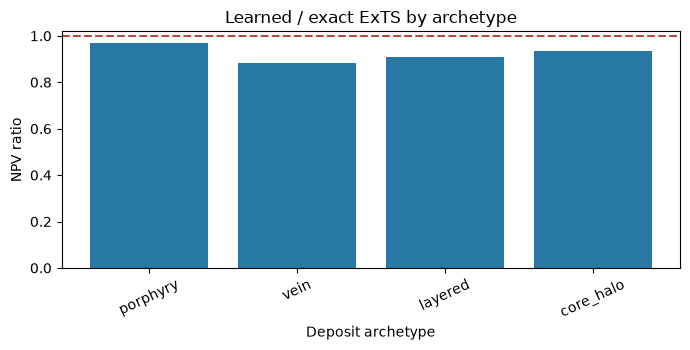

In [9]:
# Plot paired learned-to-ExTS ratios and mark equality.
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(archetypes, ratios, color='#2878a5')
ax.axhline(1.0, color='#b64b3b', linestyle='--')
ax.set(
    title='Learned / exact ExTS by archetype',
    xlabel='Deposit archetype', ylabel='NPV ratio',
)
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
plt.show()

### Figure 1

The bars compare the learned-to-ExTS NPV ratio per generated archetype. A value of 1.0 means equal schedule value on that case; below 1.0, the learned plan loses value relative to exact ExTS. The four points are a deterministic teaching sweep, not a statistical sample. A near-one ratio does not establish generalization and does not change the bound's provenance.

Now inspect the guard's held-out and clean-split recall separately. The bars use persisted study values, not the four teaching cases.

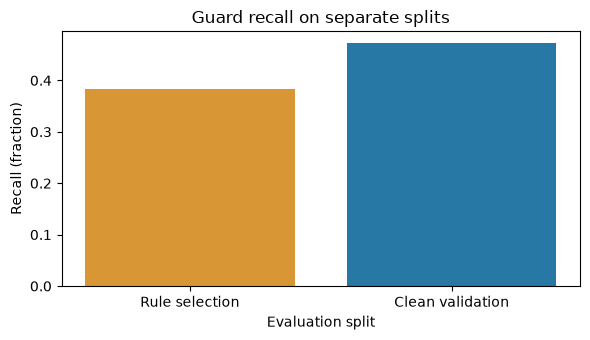

In [10]:
# Compare recall measured on the selection and clean validation splits.
fig, ax = plt.subplots(figsize=(6, 3.5))
recalls = [report['expectedTime'].get('failure_rule_recall', 0), report['guard']['validation_recall']]
ax.bar(['Rule selection', 'Clean validation'], recalls, color=['#d99635', '#2878a5'])
ax.set(
    title='Guard recall on separate splits',
    xlabel='Evaluation split', ylabel='Recall (fraction)',
)
fig.tight_layout()
plt.show()

### Figure 2

The first bar is recall on the split that informed rule selection; the second is the disjoint clean split. The clean result is below one half, so the guard misses more than half of measured failures. It is a warning rule, not a certificate. On a real deposit without a synthetic archetype label, the rule must abstain. The exact lane measures the plan directly when it finishes. The guard's false negatives are visible in the study data: the shipped archetype rule catches fewer than half of failures on both measured splits. Its rule uses an archetype label available for generated twins but unavailable for an unlabeled real deposit. Therefore this panel is evidence about the limits of the guard, not a reason to trust cases it leaves unflagged. Always wait for a direct exact-plan comparison when the production lane provides one.

The validation unit is a generated archetype, not an individual block. Randomly splitting blocks from the same synthetic deposit would leak its spatial structure into both train and test partitions and make generalization look stronger than it is. Here the held-out archetypes ask a narrower but more useful question: does a model trained on some deposit geometries retain value when the geometry changes? Four archetypes are still a small sample of geological diversity, so the ratios describe these cases and do not estimate a universal success rate.

Each ratio compares a learned feasible schedule with the exact expected-time schedule on the same instance. Pairing controls for instance scale, but a ratio near one does not mean the schedule is operationally interchangeable: precedence, destination assignment, capacity slack, and width coherence can differ. The bound predictor is evaluated separately because its role is to prioritize search. Its prediction is not a dual certificate and must never replace the exact bound when reporting an optimality gap.

The held-out guard is part of the deployment boundary. It should abstain when a feature vector or prediction error lies outside the training envelope, leaving the exact deterministic lane available. A clean split can reveal leakage or an overly permissive threshold, but cannot prove calibration under a new mine. Before using the surrogate on a new deposit, inspect feature ranges, compare paired schedule values with the exact lane, and retain the abstention rate alongside the value ratio. A useful speed-up is one that preserves a visible path back to the verified solver when the learned model is uncertain.


## Results

**Answer:** Across four generated teaching twins, the learned-to-ExTS ratio averages 0.924 and ranges from 0.881 to 0.971. On the separate clean validation split, guard recall is 0.472 with 142 failures among 432 cases; the guard misses many failures and remains a warning, not a safe-to-trust filter.

In [11]:
# Print the computed cross-case answer and clean-split guard evidence.
print(f'mean_ratio={ratios.mean():.3f}; minimum_ratio={ratios.min():.3f}')
print(f'clean_recall={report["guard"]["validation_recall"]:.3f}')

mean_ratio=0.924; minimum_ratio=0.881
clean_recall=0.472


## Summary

You compared learned and exact schedules on the same four generated deposits and retained a ratio per deposit. The clean guard recall is below 0.5, so it cannot certify unflagged cases. A trustworthy evaluation needs deposit-level disjoint splits, crossed scenarios, multiple grid sizes, failure reporting and a real-deposit check. The persisted report provides those study-level results; this lesson illustrates the evaluation path without substituting four toy cases for that evidence.

## References

- https://arxiv.org/abs/1412.6980
- https://doi.org/10.1007/s11081-012-9186-2
- PhaseFlow research: `docs/methodologies/07_learned.md` and `docs/methodologies/08_when-the-surrogate-fails.md`.